# Bundle Adjustment Example

From https://scipy-cookbook.readthedocs.io/items/bundle_adjustment.html

In [1]:
import urllib
import bz2
import os
import numpy as np

In [2]:
BASE_URL = "http://grail.cs.washington.edu/projects/bal/data/ladybug/"
FILE_NAME = "problem-49-7776-pre.txt.bz2"
URL = BASE_URL + FILE_NAME
DIR_NAME = "data"

file_path = os.path.join(DIR_NAME, FILE_NAME)


if not os.path.isfile(file_path):
    urllib.request.urlretrieve(URL, file_path)

FileNotFoundError: [Errno 2] No such file or directory: 'data/problem-49-7776-pre.txt.bz2'

In [3]:
def read_bal_data(file_name):
    with bz2.open(file_name, "rt") as file:
        n_cameras, n_points, n_observations = map(
            int, file.readline().split())

        camera_indices = np.empty(n_observations, dtype=int)
        point_indices = np.empty(n_observations, dtype=int)
        points_2d = np.empty((n_observations, 2))

        for i in range(n_observations):
            camera_index, point_index, x, y = file.readline().split()
            camera_indices[i] = int(camera_index)
            point_indices[i] = int(point_index)
            points_2d[i] = [float(x), float(y)]

        camera_params = np.empty(n_cameras * 9)
        for i in range(n_cameras * 9):
            camera_params[i] = float(file.readline())
        camera_params = camera_params.reshape((n_cameras, -1))

        points_3d = np.empty(n_points * 3)
        for i in range(n_points * 3):
            points_3d[i] = float(file.readline())
        points_3d = points_3d.reshape((n_points, -1))

    return camera_params, points_3d, camera_indices, point_indices, points_2d

In [4]:
camera_params, points_3d, camera_indices, point_indices, points_2d = read_bal_data(file_path)

In [5]:
n_cameras = camera_params.shape[0]
n_points = points_3d.shape[0]

n = 9 * n_cameras + 3 * n_points
m = 2 * points_2d.shape[0]

print("n_cameras: {}".format(n_cameras))
print("n_points: {}".format(n_points))
print("Total number of parameters: {}".format(n))
print("Total number of residuals: {}".format(m))

n_cameras: 49
n_points: 7776
Total number of parameters: 23769
Total number of residuals: 63686


In [6]:
def rotate(points, rot_vecs):
    """Rotate points by given rotation vectors.
    
    Rodrigues' rotation formula is used.
    """
    theta = np.linalg.norm(rot_vecs, axis=1)[:, np.newaxis]
    with np.errstate(invalid='ignore'):
        v = rot_vecs / theta
        v = np.nan_to_num(v)
    dot = np.sum(points * v, axis=1)[:, np.newaxis]
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)

    return cos_theta * points + sin_theta * np.cross(v, points) + dot * (1 - cos_theta) * v

In [7]:
def project(points, camera_params):
    """Convert 3-D points to 2-D by projecting onto images."""
    points_proj = rotate(points, camera_params[:, :3])
    points_proj += camera_params[:, 3:6]
    points_proj = -points_proj[:, :2] / points_proj[:, 2, np.newaxis]
    f = camera_params[:, 6]
    k1 = camera_params[:, 7]
    k2 = camera_params[:, 8]
    n = np.sum(points_proj**2, axis=1)
    r = 1 + k1 * n + k2 * n**2
    points_proj *= (r * f)[:, np.newaxis]
    return points_proj

In [8]:
def fun(params, n_cameras, n_points, camera_indices, point_indices, points_2d):
    """Compute residuals.
    
    `params` contains camera parameters and 3-D coordinates.
    """
    camera_params = params[:n_cameras * 9].reshape((n_cameras, 9))
    points_3d = params[n_cameras * 9:].reshape((n_points, 3))
    points_proj = project(points_3d[point_indices], camera_params[camera_indices])
    return (points_proj - points_2d).ravel()

In [9]:
from scipy.sparse import lil_matrix

def bundle_adjustment_sparsity(n_cameras, n_points, camera_indices, point_indices):
    m = camera_indices.size * 2
    n = n_cameras * 9 + n_points * 3
    A = lil_matrix((m, n), dtype=int)

    i = np.arange(camera_indices.size)
    for s in range(9):
        A[2 * i, camera_indices * 9 + s] = 1
        A[2 * i + 1, camera_indices * 9 + s] = 1

    for s in range(3):
        A[2 * i, n_cameras * 9 + point_indices * 3 + s] = 1
        A[2 * i + 1, n_cameras * 9 + point_indices * 3 + s] = 1

    return A

Text(0.5, 0, 'Residual')

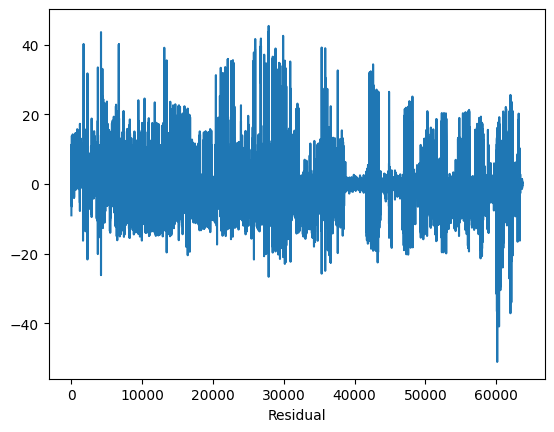

In [10]:
import matplotlib.pyplot as plt

x0 = np.hstack((camera_params.ravel(), points_3d.ravel()))
f0 = fun(x0, n_cameras, n_points, camera_indices, point_indices, points_2d)
plt.plot(f0)
plt.xlabel('Residual')

In [11]:
A = bundle_adjustment_sparsity(n_cameras, n_points, camera_indices, point_indices)

In [12]:
import time
from scipy.optimize import least_squares

t0 = time.time()
res = least_squares(fun, x0, jac_sparsity=A, verbose=2, x_scale='jac', ftol=1e-4, method='trf',
                    args=(n_cameras, n_points, camera_indices, point_indices, points_2d))
t1 = time.time()
print("Optimization took {0:.0f} seconds".format(t1 - t0))


   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         8.5091e+05                                    8.57e+06    
       1              3         5.0985e+04      8.00e+05       1.46e+02       1.15e+06    
       2              4         1.6077e+04      3.49e+04       2.59e+01       2.43e+05    
       3              5         1.4163e+04      1.91e+03       2.86e+02       1.21e+05    
       4              7         1.3695e+04      4.67e+02       1.32e+02       2.51e+04    
       5              8         1.3481e+04      2.14e+02       2.24e+02       1.54e+04    
       6              9         1.3436e+04      4.54e+01       3.18e+02       2.73e+04    
       7             10         1.3422e+04      1.38e+01       6.84e+01       2.21e+03    
       8             11         1.3418e+04      3.71e+00       1.28e+02       7.92e+03    
       9             12         1.3414e+04      4.21e+00       2.64e+01       6.21e+02    

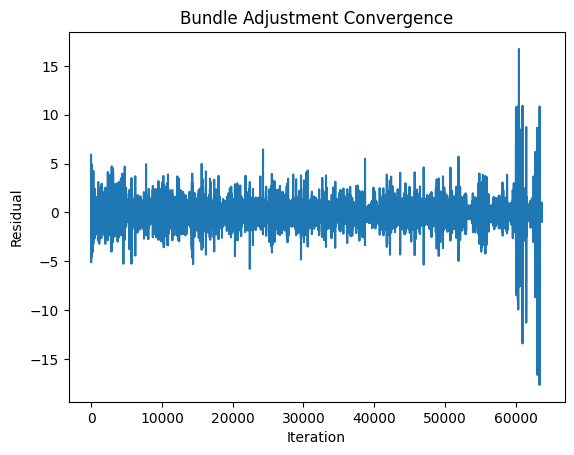

In [13]:
plt.plot(res.fun)
plt.xlabel('Iteration')
plt.ylabel('Residual')
plt.title('Bundle Adjustment Convergence')
plt.show()

Now, lets apply BA to calculate the camera positions and the 3d point positions of the ED experiment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
from argparse import ArgumentParser
from tqdm import trange

sys.path.append(os.getcwd()+"/..")

# Placeholder for your custom functions
from simulation.utils import (
    generate_unit_cell_anisotropy, 
    lattice_parameters_reciprocal,
    reciprocal_lattice_vectors, 
    random_rotate_vectors,
    generate_reciprocal_lattice,
    fibonacci_orientations,
    orientations_to_indices,
    align_reciprocal_lattice,
    simulate_diffraction_experiment,
    project_reflections_2D,
    remove_random_pairs,
    add_random_pairs,
    add_noise,
    shift_points,
    save_parameters,
    is_linear_combination,
    find_linear_independent
)


Generated unit cell parameters:
a = 6.518 Å
b = 8.825 Å
c = 7.995 Å
alpha = 103.65°
beta = 100.91°
gamma = 100.95°
Reciprocal lattice parameters:
astar = 0.200
bstar = 0.167
cstar = 0.143
alphastar = 90.000°
betastar = 90.000°
gammastar = 90.000°
True


In [2]:
target_volume = 500
volume_error = 100
a_range = [3.5, 15]
b_range = [4, 30]
c_range = [5, 45]
alpha_range = [90, 120]
beta_range = [90, 120]
gamma_range = [90, 120]
anisotropy = 1.5
resolution = 0.85
wavelength = 0.0407
excitation_error = 0.015
detector_distance = 0
edge = 1.5
fraction_limit_missing = 0.03
fraction_limit_additional = 0.05
noise_level = 0.0012
max_shift = 0.01
N = 1000
zonal_sample_threshold = 0.9
zonal_segmentation_threshold = 0.4
output_folder = "output"

# Generate unit cell parameters
a, b, c, alpha, beta, gamma = generate_unit_cell_anisotropy(
    target_volume, a_range, b_range, c_range, alpha_range, beta_range, gamma_range, volume_error, anisotropy
)

# Round the parameters
a = round(a, 3)
b = round(b, 3)
c = round(c, 3)
alpha = round(alpha, 2)
beta = round(beta, 2)
gamma = round(gamma, 2)

# Display results
print(f"Generated unit cell parameters:")
print(f"a = {a:.3f} Å")
print(f"b = {b:.3f} Å")
print(f"c = {c:.3f} Å")
print(f"alpha = {alpha:.2f}°")
print(f"beta = {beta:.2f}°")
print(f"gamma = {gamma:.2f}°")


# Compute reciprocal lattice parameters
astar, bstar, cstar, alphastar, betastar, gammastar = lattice_parameters_reciprocal(a, b, c, alpha, beta, gamma)
v1, v2, v3 = reciprocal_lattice_vectors(astar, bstar, cstar, alphastar, betastar, gammastar)

astar_rot, bstar_rot, cstar_rot = random_rotate_vectors(v1, v2, v3)

# Generate reciprocal lattice reflections
hkl_list, reflections = generate_reciprocal_lattice(v1, v2, v3, resolution)

orientations = fibonacci_orientations(N)
indices = orientations_to_indices(orientations, astar_rot, bstar_rot, cstar_rot)
# Parameters
R = 1 / wavelength

# Compute Ewald sphere
theta, phi = np.meshgrid(np.linspace(0, np.pi, 50), np.linspace(0, 2 * np.pi, 100))
X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

# Shift the sphere to the Ewald center
X = X + 0
Y = Y + 0
Z = Z + R


Generated unit cell parameters:
a = 11.108 Å
b = 7.945 Å
c = 7.953 Å
alpha = 111.74°
beta = 106.36°
gamma = 119.00°


In [3]:
i = 0
rotated_reflections = align_reciprocal_lattice(reflections, orientations[i, :])
ewald_sphere, diffraction_spots, hkl_included = simulate_diffraction_experiment(hkl_list, rotated_reflections, wavelength, excitation_error)

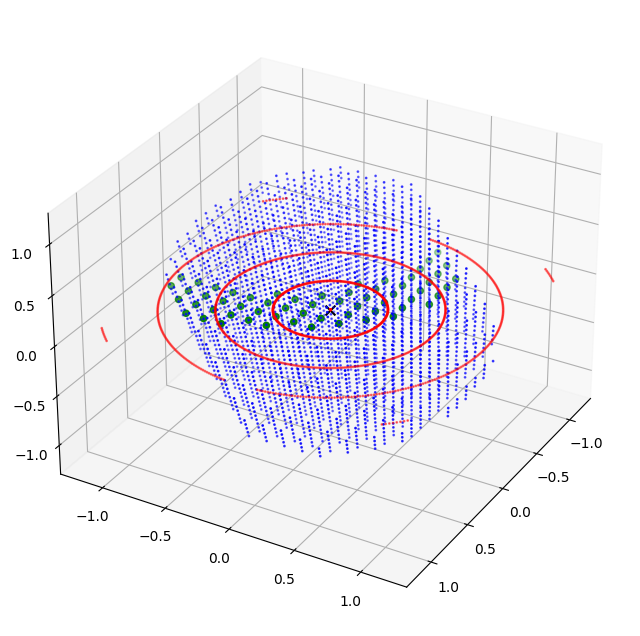

In [4]:
import matplotlib.pyplot as plt

reflection_bounds = np.concatenate([np.min(reflections, axis=0), np.max(reflections, axis=0)])
ewald_sphere_viz = ewald_sphere[(ewald_sphere[:, 0] >= reflection_bounds[0]) & (ewald_sphere[:, 0] <= reflection_bounds[3]) &
                             (ewald_sphere[:, 1] >= reflection_bounds[1]) & (ewald_sphere[:, 1] <= reflection_bounds[4]) &
                             (ewald_sphere[:, 2] >= reflection_bounds[2]) & (ewald_sphere[:, 2] <= reflection_bounds[5])]



ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(reflections[:, 0], reflections[:, 1], reflections[:, 2], color='blue', label='Reflections', s=1)
ax.scatter(ewald_sphere_viz[:, 0], ewald_sphere_viz[:, 1], ewald_sphere_viz[:, 2], color='red', label='Ewald Sphere', s=1, alpha=0.5)
ax.scatter(diffraction_spots[:, 0], diffraction_spots[:, 1], diffraction_spots[:, 2], color='green', label='Diffraction Spots', s=20)

center = np.array([0, 0, 0])
ax.scatter(center[0], center[1], center[2], color='black', label='Ewald Center', s=50, marker='x')
ax.view_init(elev=30, azim=30)


In [5]:
camera_direction = orientations[i, :]
camera_position = camera_direction * 1 / wavelength * 0.1
center = np.array([0.0, 0.0, 0.0])
dir_vec = center - camera_position
dir_unit = dir_vec / np.linalg.norm(dir_vec)

z_axis = np.array([0.0, 0.0, 1.0])
v = np.cross(z_axis, dir_unit)
s = np.linalg.norm(v)
c = np.dot(z_axis, dir_unit)
if s < 1e-8:
    rot_mat = np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
else:
    K = np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])
    rot_mat = np.eye(3) + K + K @ K * ((1.0 - c) / (s**2))

camera_extrinsics = np.eye(4)
camera_extrinsics[:3, :3] = rot_mat
camera_extrinsics[:3, 3] = camera_position

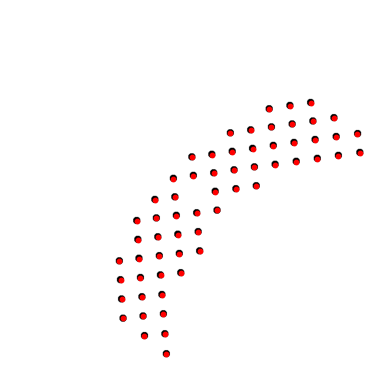

In [6]:
import cv2 

canvas_size = 1000
focal_length = canvas_size * 1
K_intrinsic = np.array([[focal_length, 0, canvas_size // 2], [0, focal_length, canvas_size // 2], [0, 0, 1]])
T_extrinsics = np.linalg.inv(camera_extrinsics)

world_pts_homogeneous = np.hstack([diffraction_spots, np.ones((diffraction_spots.shape[0], 1))])
projected_pts_homogeneous = ((K_intrinsic @ T_extrinsics[:3, :]) @ world_pts_homogeneous.T).T
projected_x = projected_pts_homogeneous[:, 0] / projected_pts_homogeneous[:, 2]
projected_y = projected_pts_homogeneous[:, 1] / projected_pts_homogeneous[:, 2]
depth = projected_pts_homogeneous[:, 2]


canvas = np.ones((canvas_size, canvas_size), dtype=np.uint8) * 255
depth_map = np.full((canvas_size, canvas_size), np.inf)

meshgrid_x, meshgrid_y = np.meshgrid(np.arange(canvas_size), np.arange(canvas_size))
meshgrid_points = np.stack([meshgrid_x, meshgrid_y], axis=-1).reshape(-1, 2)
for x, y, d in zip(projected_x, projected_y, depth):
    if 0 <= x < canvas.shape[1] and 0 <= y < canvas.shape[0]:
        circle_radius = 10
        circle_center = np.array([x, y], dtype=np.int32)
        canvas[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = 0
        depth_map[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = d

center = np.array([0, 0, 0])

plt.imshow(canvas, cmap='gray')
plt.axis('off')
plt.scatter(projected_x, projected_y, color='red', s=10)



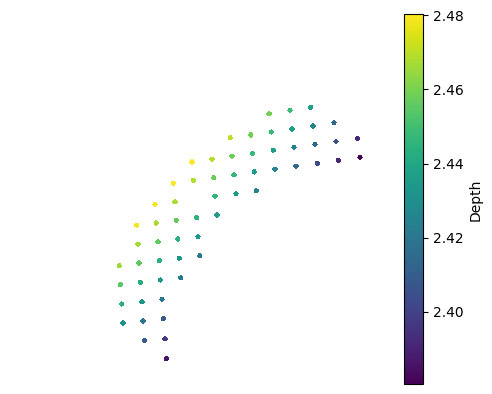

In [7]:
plt.imshow(depth_map, cmap='viridis')
plt.colorbar(label='Depth')
plt.axis('off')
plt.show()

In [26]:
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from scipy.optimize import least_squares
from scipy.spatial.transform import Rotation


# ============================================================
# Data structures
# ============================================================

@dataclass
class ExpImage:
    projected_x: np.ndarray
    projected_y: np.ndarray
    depth: np.ndarray

    @property
    def uv(self):
        return np.column_stack([
            np.asarray(self.projected_x, dtype=float),
            np.asarray(self.projected_y, dtype=float),
        ])


@dataclass
class LatticeFitResult:
    B: np.ndarray
    pose_rotvecs: np.ndarray
    hkls: list[np.ndarray]
    inlier_masks: list[np.ndarray]
    cost_history: list[float]


# ============================================================
# Camera model
# ============================================================

def camera_from_rotvec(rotvec, camera_distance):
    """
    rotvec defines camera-to-world rotation.

    Camera optical axis is +z.

    The camera lies on a sphere with radius camera_distance
    and always points toward the world origin.

    Therefore:

        camera_position = -distance * optical_axis
    """

    R_cw = Rotation.from_rotvec(rotvec).as_matrix()

    forward = R_cw[:, 2]

    camera_position = -camera_distance * forward

    return R_cw, camera_position


def camera_rotation_from_angles(azimuth, elevation, roll):
    """
    Construct camera-to-world rotation from

        azimuth
        elevation
        roll

    Camera lies on a sphere around the origin and looks toward
    the origin.
    """

    camera_direction = np.array([
        np.cos(elevation) * np.cos(azimuth),
        np.cos(elevation) * np.sin(azimuth),
        np.sin(elevation),
    ])

    # Camera looks from its position toward origin
    forward = -camera_direction

    up = np.array([0.0, 0.0, 1.0])

    # Avoid singularity
    if abs(np.dot(forward, up)) > 0.99:
        up = np.array([0.0, 1.0, 0.0])

    right = np.cross(forward, up)
    right /= np.linalg.norm(right)

    down = np.cross(forward, right)
    down /= np.linalg.norm(down)

    R0 = np.column_stack([
        right,
        down,
        forward,
    ])

    # roll around optical axis
    cr = np.cos(roll)
    sr = np.sin(roll)

    R_roll = np.array([
        [cr, -sr, 0],
        [sr,  cr, 0],
        [0,    0, 1],
    ])

    return R0 @ R_roll


def rotvec_to_angles(rotvec, camera_distance=1.0):
    """
    Convert optimized rotation vector back to

        azimuth, elevation, roll

    in radians.
    """

    R_cw, C = camera_from_rotvec(
        rotvec,
        camera_distance,
    )

    direction = C / np.linalg.norm(C)

    azimuth = np.arctan2(
        direction[1],
        direction[0],
    )

    elevation = np.arcsin(
        np.clip(direction[2], -1, 1)
    )

    R0 = camera_rotation_from_angles(
        azimuth,
        elevation,
        0,
    )

    R_relative = R0.T @ R_cw

    roll = np.arctan2(
        R_relative[1, 0],
        R_relative[0, 0],
    )

    return azimuth, elevation, roll


# ============================================================
# Projection
# ============================================================

def project_world_points(
    xyz,
    rotvec,
    K,
    camera_distance,
):
    """
    Project reciprocal-space points onto image.
    """

    R_cw, C = camera_from_rotvec(
        rotvec,
        camera_distance,
    )

    R_wc = R_cw.T

    xyz_camera = (
        R_wc @ (xyz - C).T
    ).T

    depth = xyz_camera[:, 2]

    projected = (
        K @ xyz_camera.T
    ).T

    uv = (
        projected[:, :2]
        / projected[:, 2:3]
    )

    return uv, depth


# ============================================================
# Pixel -> Ewald sphere
# ============================================================

def backproject_pixels_to_ewald(
    uv,
    rotvec,
    K,
    wavelength,
    camera_distance,
):
    """
    Intersect every image ray with the Ewald sphere.

    Sphere:

        radius = 1 / wavelength

        center = [0, 0, radius]

    Returns
    -------
    q
        approximate reciprocal-space points

    miss
        distance by which a ray misses the Ewald sphere
    """

    uv = np.asarray(uv)

    n = len(uv)

    R_cw, C = camera_from_rotvec(
        rotvec,
        camera_distance,
    )

    K_inv = np.linalg.inv(K)

    # pixels -> rays in camera coordinates
    pixels_h = np.column_stack([
        uv,
        np.ones(n),
    ])

    rays_camera = (
        K_inv @ pixels_h.T
    ).T

    rays_camera /= np.linalg.norm(
        rays_camera,
        axis=1,
        keepdims=True,
    )

    # camera -> world
    rays_world = (
        rays_camera @ R_cw.T
    )

    # Ewald sphere
    R = 1.0 / wavelength

    sphere_center = np.array([
        0.0,
        0.0,
        R,
    ])

    oc = C - sphere_center

    #
    # Intersection:
    #
    # |C + t*d - S|² = R²
    #
    # t² + b t + c = 0
    #

    b = 2 * (rays_world @ oc)

    c = (
        np.dot(oc, oc)
        - R**2
    )

    discriminant = (
        b**2
        - 4 * c
    )

    sqrt_disc = np.sqrt(
        np.maximum(
            discriminant,
            0,
        )
    )

    t1 = (-b - sqrt_disc) / 2
    t2 = (-b + sqrt_disc) / 2

    eps = 1e-9

    valid1 = (
        (discriminant >= 0)
        & (t1 > eps)
    )

    valid2 = (
        (discriminant >= 0)
        & (t2 > eps)
    )

    t = np.full(n, np.nan)

    both = valid1 & valid2

    t[both] = np.minimum(
        t1[both],
        t2[both],
    )

    only1 = valid1 & ~valid2
    only2 = valid2 & ~valid1

    t[only1] = t1[only1]
    t[only2] = t2[only2]

    valid = np.isfinite(t)

    # If the ray misses the sphere, use closest
    # approach as a fallback.
    t_closest = np.maximum(
        -b / 2,
        eps,
    )

    t = np.where(
        valid,
        t,
        t_closest,
    )

    q = (
        C[None, :]
        + t[:, None] * rays_world
    )

    # distance from infinite line to sphere
    projection = (
        rays_world @ oc
    )

    line_distance_squared = np.maximum(
        np.dot(oc, oc)
        - projection**2,
        0,
    )

    line_distance = np.sqrt(
        line_distance_squared
    )

    miss = np.maximum(
        line_distance - R,
        0,
    )

    return q, miss


# ============================================================
# Integer indexing
# ============================================================

def assign_hkls(
    q,
    B,
    hkl_max=None,
):
    """
    Given reciprocal coordinates q, find closest integer HKL.

        q = B @ hkl

    therefore

        hkl ~= B^-1 q
    """

    fractional_hkl = np.linalg.solve(
        B,
        q.T,
    ).T

    hkl = np.rint(
        fractional_hkl
    ).astype(int)

    reconstructed = (
        hkl @ B.T
    )

    error = np.linalg.norm(
        q - reconstructed,
        axis=1,
    )

    valid = np.ones(
        len(q),
        dtype=bool,
    )

    # Remove direct beam
    valid &= np.any(
        hkl != 0,
        axis=1,
    )

    if hkl_max is not None:
        valid &= (
            np.max(
                np.abs(hkl),
                axis=1,
            )
            <= hkl_max
        )

    return hkl, error, valid


# ============================================================
# Single-image pose optimization
# ============================================================

def pose_residual(
    rotvec,
    uv,
    hkl,
    B,
    K,
    wavelength,
    camera_distance,
    sigma,
):
    """
    Smooth residual with FIXED HKL assignment.

        pixel
          ↓
       Ewald
          ↓
          q

    and

        q ≈ B @ hkl
    """

    q, miss = backproject_pixels_to_ewald(
        uv,
        rotvec,
        K,
        wavelength,
        camera_distance,
    )

    target = (
        hkl @ B.T
    )

    residual_xyz = (
        q - target
    ) / sigma

    residual_miss = (
        miss[:, None]
        / sigma
    )

    return np.hstack([
        residual_xyz,
        residual_miss,
    ]).ravel()


def pose_score(
    rotvec,
    uv,
    B,
    K,
    wavelength,
    camera_distance,
    hkl_max,
):
    """
    Score an orientation using nearest-lattice distance.
    """

    q, miss = backproject_pixels_to_ewald(
        uv,
        rotvec,
        K,
        wavelength,
        camera_distance,
    )

    _, error, valid = assign_hkls(
        q,
        B,
        hkl_max,
    )

    if not np.any(valid):
        return np.inf

    return (
        np.median(error[valid])
        + 10 * np.mean(miss)
    )


def optimize_image_pose(
    image,
    B,
    K,
    wavelength,
    camera_distance,
    rotvec_init=None,
    reciprocal_sigma=0.005,
    hkl_max=None,
    n_restarts=8,
    assignment_iterations=4,
    rng=None,
):
    """
    Estimate azimuth/elevation/roll for one image.

    We alternate:

        pose
          ↓
       assign HKL
          ↓
    optimize pose with fixed HKL
          ↓
       reassign HKL
    """

    if rng is None:
        rng = np.random.default_rng()

    uv = image.uv

    starts = []

    if rotvec_init is not None:
        starts.append(
            np.asarray(
                rotvec_init,
                dtype=float,
            )
        )

    # Unknown camera orientation:
    # random initialization is used ONLY for the 3-DOF camera pose.
    #
    # We are not randomly searching lattice parameters.
    while len(starts) < n_restarts:

        azimuth = rng.uniform(
            -np.pi,
            np.pi,
        )

        elevation = np.arcsin(
            rng.uniform(-1, 1)
        )

        roll = rng.uniform(
            -np.pi,
            np.pi,
        )

        R = camera_rotation_from_angles(
            azimuth,
            elevation,
            roll,
        )

        starts.append(
            Rotation
            .from_matrix(R)
            .as_rotvec()
        )

    best_pose = None
    best_score = np.inf

    for initial_pose in starts:

        pose = initial_pose.copy()

        for _ in range(
            assignment_iterations
        ):

            # ----------------------
            # Assign HKLs
            # ----------------------

            q, _ = backproject_pixels_to_ewald(
                uv,
                pose,
                K,
                wavelength,
                camera_distance,
            )

            hkl, _, _ = assign_hkls(
                q,
                B,
                hkl_max,
            )

            # ----------------------
            # Optimize pose
            # ----------------------

            result = least_squares(
                pose_residual,
                pose,

                args=(
                    uv,
                    hkl,
                    B,
                    K,
                    wavelength,
                    camera_distance,
                    reciprocal_sigma,
                ),

                loss="soft_l1",
                f_scale=1.0,

                x_scale="jac",

                max_nfev=150,
            )

            pose = result.x

        score = pose_score(
            pose,
            uv,
            B,
            K,
            wavelength,
            camera_distance,
            hkl_max,
        )

        if score < best_score:

            best_score = score
            best_pose = pose.copy()

    return best_pose, best_score


# ============================================================
# Reciprocal basis optimization
# ============================================================

def robust_update_basis(
    Q,
    H,
    B_previous,
    sigma,
):
    """
    Solve

        Q ~= H B^T

    where

        Q : Nx3 reciprocal points
        H : Nx3 integer HKLs
    """

    if np.linalg.matrix_rank(H) < 3:
        raise ValueError(
            "HKL observations do not span 3 dimensions."
        )

    # Initial linear least squares
    B_T, *_ = np.linalg.lstsq(
        H,
        Q,
        rcond=None,
    )

    B0 = B_T.T

    def residual(x):

        B = x.reshape(3, 3)

        predicted = (
            H @ B.T
        )

        return (
            (predicted - Q)
            / sigma
        ).ravel()

    result = least_squares(
        residual,
        B0.ravel(),

        loss="soft_l1",
        f_scale=1.0,

        x_scale="jac",

        max_nfev=300,
    )

    B = result.x.reshape(3, 3)

    if abs(np.linalg.det(B)) < 1e-10:
        return B_previous

    return B


# ============================================================
# Final bundle-adjustment-like optimization
# ============================================================

def joint_reprojection_residual(
    x,
    images,
    hkls,
    masks,
    K,
    wavelength,
    camera_distance,
    pixel_sigma,
    excitation_sigma,
    ewald_weight,
):

    number_images = len(images)

    B = x[:9].reshape(3, 3)

    poses = x[9:].reshape(
        number_images,
        3,
    )

    R_ewald = 1 / wavelength

    ewald_center = np.array([
        0,
        0,
        R_ewald,
    ])

    residuals = []

    for i, image in enumerate(images):

        mask = masks[i]

        if not np.any(mask):
            continue

        uv_observed = (
            image.uv[mask]
        )

        hkl = (
            hkls[i][mask]
        )

        # predicted reciprocal point
        xyz = (
            hkl @ B.T
        )

        # project into image
        uv_predicted, depth = (
            project_world_points(
                xyz,
                poses[i],
                K,
                camera_distance,
            )
        )

        # ----------------------------------
        # Main objective:
        # pixel reprojection error
        # ----------------------------------

        reprojection_error = (
            uv_predicted
            - uv_observed
        ) / pixel_sigma

        residuals.append(
            reprojection_error.ravel()
        )

        # ----------------------------------
        # Ewald constraint
        # ----------------------------------

        if ewald_weight > 0:

            ewald_error = (
                np.linalg.norm(
                    xyz - ewald_center,
                    axis=1,
                )
                - R_ewald
            )

            residuals.append(
                ewald_weight
                * ewald_error
                / excitation_sigma
            )

        # Keep points in front of camera
        depth_error = np.maximum(
            -depth,
            0,
        )

        residuals.append(
            depth_error
        )

    return np.concatenate(
        residuals
    )


# ============================================================
# Main optimizer
# ============================================================

def fit_reciprocal_lattice(
    images,
    B_init,
    K,
    wavelength,
    camera_distance,
    pose_init=None,
    outer_iterations=8,
    n_pose_restarts=8,
    hkl_max=None,
    indexing_threshold=None,
    reciprocal_sigma=None,
    pixel_sigma=1.0,
    excitation_sigma=0.015,
    ewald_weight=0.2,
    random_seed=0,
):

    rng = np.random.default_rng(
        random_seed
    )

    B = np.asarray(
        B_init,
        dtype=float,
    ).copy()

    n_images = len(images)

    # ------------------------------------------------
    # Initialize camera poses
    # ------------------------------------------------

    if pose_init is None:

        poses = np.full(
            (n_images, 3),
            np.nan,
        )

    else:

        poses = np.asarray(
            pose_init,
            dtype=float,
        ).copy()

    reciprocal_spacing = np.min(
        np.linalg.norm(
            B,
            axis=0,
        )
    )

    if reciprocal_sigma is None:
        reciprocal_sigma = (
            0.05
            * reciprocal_spacing
        )

    if indexing_threshold is None:
        indexing_threshold = (
            0.20
            * reciprocal_spacing
        )

    history = []

    hkls = [None] * n_images
    masks = [None] * n_images

    # ========================================================
    # Alternating optimization
    # ========================================================

    for iteration in range(
        outer_iterations
    ):

        all_q = []
        all_hkl = []

        assignment_errors = []

        # ----------------------------------------------------
        # A. Optimize each camera independently
        # ----------------------------------------------------

        for i, image in enumerate(images):

            if np.any(
                np.isnan(poses[i])
            ):
                pose_guess = None
            else:
                pose_guess = poses[i]

            # Random restarts needed mainly initially.
            restarts = (
                n_pose_restarts
                if pose_guess is None
                else 1
            )

            pose, score = optimize_image_pose(
                image=image,
                B=B,
                K=K,

                wavelength=wavelength,

                camera_distance=camera_distance,

                rotvec_init=pose_guess,

                reciprocal_sigma=reciprocal_sigma,

                hkl_max=hkl_max,

                n_restarts=restarts,

                rng=rng,
            )

            poses[i] = pose

            # ------------------------------------------------
            # Reconstruct reciprocal points
            # ------------------------------------------------

            q, miss = (
                backproject_pixels_to_ewald(
                    image.uv,
                    pose,
                    K,
                    wavelength,
                    camera_distance,
                )
            )

            # ------------------------------------------------
            # Integer indexing
            # ------------------------------------------------

            hkl, error, valid = (
                assign_hkls(
                    q,
                    B,
                    hkl_max,
                )
            )

            inlier = (
                valid
                & (
                    error
                    < indexing_threshold
                )
                & (
                    miss
                    < reciprocal_sigma
                )
            )

            hkls[i] = hkl
            masks[i] = inlier

            if np.any(inlier):

                all_q.append(
                    q[inlier]
                )

                all_hkl.append(
                    hkl[inlier]
                )

                assignment_errors.extend(
                    error[inlier]
                )

        if len(all_q) == 0:

            raise RuntimeError(
                "No valid lattice points found. "
                "B_init is probably too far from the "
                "correct reciprocal lattice."
            )

        Q = np.vstack(all_q)
        H = np.vstack(all_hkl)

        # ----------------------------------------------------
        # B. Update reciprocal lattice
        # ----------------------------------------------------

        B = robust_update_basis(
            Q,
            H,
            B_previous=B,
            sigma=reciprocal_sigma,
        )

        mean_error = np.mean(
            assignment_errors
        )

        history.append(
            mean_error
        )

        print(
            f"iteration {iteration:02d}: "
            f"inliers={len(Q):5d}, "
            f"mean error={mean_error:.6f}"
        )

    # ========================================================
    # Final joint optimization
    # ========================================================

    print(
        "\nStarting joint reprojection refinement..."
    )

    x0 = np.concatenate([
        B.ravel(),
        poses.ravel(),
    ])

    result = least_squares(
        joint_reprojection_residual,
        x0,

        args=(
            images,
            hkls,
            masks,
            K,
            wavelength,
            camera_distance,
            pixel_sigma,
            excitation_sigma,
            ewald_weight,
        ),

        loss="soft_l1",
        f_scale=1.0,

        x_scale="jac",

        max_nfev=2000,

        verbose=1,
    )

    B_final = (
        result.x[:9]
        .reshape(3, 3)
    )

    poses_final = (
        result.x[9:]
        .reshape(n_images, 3)
    )

    return LatticeFitResult(
        B=B_final,
        pose_rotvecs=poses_final,
        hkls=hkls,
        inlier_masks=masks,
        cost_history=history,
    )


# ============================================================
# Reciprocal basis -> conventional cell parameters
# ============================================================

def direct_cell_from_reciprocal_basis(B):
    """
    Assumes reciprocal vectors use 1/Angstrom,
    not 2*pi/Angstrom.

        B = A^{-T}

    therefore

        A = B^{-T}
    """

    A = np.linalg.inv(B).T

    a_vec = A[:, 0]
    b_vec = A[:, 1]
    c_vec = A[:, 2]

    a = np.linalg.norm(a_vec)
    b = np.linalg.norm(b_vec)
    c = np.linalg.norm(c_vec)

    def angle(u, v):

        cosine = (
            np.dot(u, v)
            / (
                np.linalg.norm(u)
                * np.linalg.norm(v)
            )
        )

        return np.degrees(
            np.arccos(
                np.clip(
                    cosine,
                    -1,
                    1,
                )
            )
        )

    alpha = angle(
        b_vec,
        c_vec,
    )

    beta = angle(
        a_vec,
        c_vec,
    )

    gamma = angle(
        a_vec,
        b_vec,
    )

    return (
        a,
        b,
        c,
        alpha,
        beta,
        gamma,
    )

In [27]:
def extrinsics_from_angles(azimuth, elevation, rotation: float, wavelength: float):
    camera_direction = np.array([
        np.cos(elevation) * np.cos(azimuth),
        np.cos(elevation) * np.sin(azimuth),
        np.sin(elevation)
    ])

    camera_position = camera_direction * 1 / wavelength * 0.1

    center = np.array([0.0, 0.0, 0.0])
    dir_vec = center - camera_position
    dir_unit = dir_vec / np.linalg.norm(dir_vec)

    # Rotation that aligns local camera Z with dir_unit
    z_axis = np.array([0.0, 0.0, 1.0])
    v = np.cross(z_axis, dir_unit)
    s = np.linalg.norm(v)
    c = np.dot(z_axis, dir_unit)

    if s < 1e-8:
        rot_mat = np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    else:
        K = np.array([
            [0.0,   -v[2],  v[1]],
            [v[2],   0.0,  -v[0]],
            [-v[1],  v[0],  0.0]
        ])

        rot_mat = (
            np.eye(3)
            + K
            + K @ K * ((1.0 - c) / (s**2))
        )

    # ---------------------------------------------------------
    # Roll around the CAMERA's local Z axis
    # ---------------------------------------------------------
    R_roll = np.array([
        [np.cos(rotation), -np.sin(rotation), 0.0],
        [np.sin(rotation),  np.cos(rotation), 0.0],
        [0.0,               0.0,              1.0]
    ])

    # Apply roll in camera-local coordinates
    rot_mat = rot_mat @ R_roll

    camera_extrinsics = np.eye(4)
    camera_extrinsics[:3, :3] = rot_mat
    camera_extrinsics[:3, 3] = camera_position

    T_extrinsics = np.linalg.inv(camera_extrinsics)

    return T_extrinsics

def azimuth_elevation_from_extrinsics(T_extrinsics):
    camera_position = T_extrinsics[:3, 3]
    camera_direction = -T_extrinsics[:3, :3].T @ np.array([0.0, 0.0, 1.0])
    azimuth = np.arctan2(camera_direction[1], camera_direction[0])
    elevation = np.arcsin(camera_direction[2] / np.linalg.norm(camera_direction))
    return azimuth, elevation

azimuth, elevation = azimuth_elevation_from_extrinsics(T_extrinsics)
print(f"Azimuth: {np.degrees(azimuth):.2f} degrees, Elevation: {np.degrees(elevation):.2f} degrees")

calculated_T_extrinsics = extrinsics_from_angles(azimuth, elevation, 0.0, wavelength)

print("Difference between original T_extrinsics and calculated T_extrinsics:")
print(np.mean(T_extrinsics - calculated_T_extrinsics))

Azimuth: -137.51 degrees, Elevation: 86.38 degrees
Difference between original T_extrinsics and calculated T_extrinsics:
1.0875269685347844e-17


In [28]:
def project_points(points, intrinsics, extrinsics):
    world_pts_homogeneous = np.hstack([points, np.ones((points.shape[0], 1))])
    projected_pts_homogeneous = ((intrinsics @ extrinsics[:3, :]) @ world_pts_homogeneous.T).T
    projected_x = projected_pts_homogeneous[:, 0] / projected_pts_homogeneous[:, 2]
    projected_y = projected_pts_homogeneous[:, 1] / projected_pts_homogeneous[:, 2]
    depth = projected_pts_homogeneous[:, 2]
    return projected_x, projected_y, depth


def calculate_projection(points, T_extrinsics, K_intrinsic, radius=1e-3, tolerance=1e-6):
    points_selected = points[np.linalg.norm(points - T_extrinsics[:3, 3], axis=1) < radius + tolerance]
    projected_x, projected_y, depth = project_points(points_selected, K_intrinsic, T_extrinsics)
    # cut using radius of edwald sphere
    idx = np.where(np.logical_and(depth < radius + tolerance, depth > radius - tolerance))[0]
    return projected_x[idx], projected_y[idx], depth[idx]


T_extrinsics = extrinsics_from_angles(azimuth, elevation, 0.0, wavelength)
calculate_projection(points=reflections, T_extrinsics=T_extrinsics, K_intrinsic=K_intrinsic, radius=1/wavelength * 0.1, tolerance=excitation_error)


(array([508.829, 449.703, 391.12 , 504.404, 445.438, 559.352, 441.193,
        554.808, 495.617, 609.862, 550.284, 491.254]),
 array([601.771, 557.82 , 514.272, 550.765, 507.152, 543.678, 456.724,
        492.816, 449.475, 485.599, 442.195, 399.189]),
 array([2.445, 2.457, 2.468, 2.451, 2.463, 2.446, 2.468, 2.451, 2.463,
        2.446, 2.457, 2.469]))

In [ ]:
# sample orientations using Fibonacci sphere
def fibonacci_orientations(n):
    indices = np.arange(0, n, dtype=float) + 0.5
    phi = np.arccos(1 - 2 * indices / n)
    theta = np.pi * (1 + 5**0.5) * indices
    x = np.sin(phi) * np.cos(theta)
    y = np.sin(phi) * np.sin(theta)
    z = np.cos(phi)
    azimuth = np.arctan2(y, x)
    elevation = np.arcsin(z)
    roll = np.random.uniform(-np.pi, np.pi, size=n)
    return np.column_stack((azimuth, elevation, roll))

orientations = fibonacci_orientations(20)
orientations

array([[-1.2  ,  1.253,  0.684],
       [ 2.683,  1.016,  0.254],
       [ 0.283,  0.848,  2.436],
       [-2.117,  0.708, -1.875],
       [ 1.767,  0.582, -2.724],
       [-0.633,  0.467,  2.932],
       [-3.033,  0.358,  0.504],
       [ 0.85 ,  0.253, -1.288],
       [-1.55 ,  0.151,  1.863],
       [ 2.333,  0.05 , -1.719],
       [-0.067, -0.05 ,  1.063],
       [-2.467, -0.151, -2.635],
       [ 1.416, -0.253,  2.034],
       [-0.984, -0.358,  3.049],
       [ 2.9  , -0.467,  0.62 ],
       [ 0.5  , -0.582,  1.331],
       [-1.9  , -0.708,  0.7  ],
       [ 1.983, -0.848, -2.814],
       [-0.417, -1.016,  1.539],
       [-2.817, -1.253,  0.688]])

In [36]:
images = [
    ExpImage(projected_x=projected_x, projected_y=projected_y, depth=depth)
    for projected_x, projected_y, depth in [calculate_projection(points=reflections, T_extrinsics=extrinsics_from_angles(azimuth, elevation, roll, wavelength), K_intrinsic=K_intrinsic, radius=1/wavelength * 0.1, tolerance=excitation_error) for azimuth, elevation, roll in orientations]
]

canvas_size = 1000
focal_length = canvas_size

K = np.array([
    [focal_length, 0, canvas_size / 2],
    [0, focal_length, canvas_size / 2],
    [0, 0, 1],
])

wavelength = 0.0407

camera_distance = (
    1 / wavelength
) * 0.1

B_true = np.column_stack([
    v1,
    v2,
    v3,
])

B_init = B_true @ np.array([
    [1.05,  0.02, 0.00],
    [0.00,  0.95, 0.01],
    [0.01, -0.02, 1.03],
])

fit = fit_reciprocal_lattice(
    images=images,

    B_init=B_init,

    K=K,

    wavelength=0.0407,

    camera_distance=camera_distance,

    outer_iterations=10,

    n_pose_restarts=16,

    excitation_sigma=0.015,

    pixel_sigma=1.0,
)

iteration 00: inliers=  107, mean error=0.017393


ValueError: HKL observations do not span 3 dimensions.

We can actually estimate the depth of each pixel, by its distance from the camera (The Edwald Sphere).

In [82]:
def project_to_world(projected_x, projected_y, depth, intrinsics, extrinsics):
    projected_pts_homogeneous = np.stack([projected_x * depth, projected_y * depth, depth, np.ones_like(depth)], axis=-1)
    intrinsic_hom = np.eye(4)
    intrinsic_hom[:3, :3] = intrinsics
    world_pts_homogeneous = np.linalg.inv(intrinsic_hom @ extrinsics) @ projected_pts_homogeneous.T
    world_pts_homogeneous /= world_pts_homogeneous[3, :]
    return world_pts_homogeneous[:3, :].T

original_world_pts = project_to_world(projected_x, projected_y, depth, K_intrinsic, T_extrinsics)
constant_depth_world_pts = project_to_world(projected_x, projected_y, np.ones_like(projected_x)*1/wavelength*0.1, K_intrinsic, T_extrinsics)

print("Difference between original world points and diffraction spots:")
print(np.mean(original_world_pts - diffraction_spots))
print("Difference between constant depth world points and diffraction spots:")
print(np.mean(constant_depth_world_pts - diffraction_spots))

Difference between original world points and diffraction spots:
-8.646999929723545e-17
Difference between constant depth world points and diffraction spots:
-0.00732384598832344


We see that an estimation of constant depth is on average not far off from the actual positions of the points.

In [83]:
def project_points(points, intrinsics, extrinsics):
    world_pts_homogeneous = np.hstack([points, np.ones((points.shape[0], 1))])
    projected_pts_homogeneous = ((intrinsics @ extrinsics[:3, :]) @ world_pts_homogeneous.T).T
    projected_x = projected_pts_homogeneous[:, 0] / projected_pts_homogeneous[:, 2]
    projected_y = projected_pts_homogeneous[:, 1] / projected_pts_homogeneous[:, 2]
    depth = projected_pts_homogeneous[:, 2]
    return projected_x, projected_y, depth

def draw_canvas(projected_x, projected_y, depth, canvas_size):
    canvas = np.ones((canvas_size, canvas_size), dtype=np.uint8) * 255
    depth_map = np.full((canvas_size, canvas_size), np.inf)

    meshgrid_x, meshgrid_y = np.meshgrid(np.arange(canvas_size), np.arange(canvas_size))
    for x, y, d in zip(projected_x, projected_y, depth):
        if 0 <= x < canvas.shape[1] and 0 <= y < canvas.shape[0]:
            circle_radius = 10
            circle_center = np.array([x, y], dtype=np.int32)
            canvas[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = 0
            depth_map[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = d
    return canvas, depth_map

def residual(points, projected_x, projected_y, depth, intrinsics, extrinsics):
    projected_x_calc, projected_y_calc, depth_calc = project_points(points, intrinsics, extrinsics)
    return np.stack([projected_x_calc - projected_x, projected_y_calc - projected_y, depth_calc - depth], axis=-1)

np.sum(residual(diffraction_spots, projected_x, projected_y, depth, K_intrinsic, T_extrinsics))

0.0

Since all cameras are equidistant and have the same intrinsic parameters, we only azimuth and elivation of the spherical coordinates for all cameras. Also all points are calculated using the same edwald sphere only shifted by camera position, so we can calculate the projection using only `azimuth` and `elevtaion`.

In [84]:
def extrinsics_from_angles(azimuth, elevation, rotation: float, wavelength: float):
    camera_direction = np.array([
        np.cos(elevation) * np.cos(azimuth),
        np.cos(elevation) * np.sin(azimuth),
        np.sin(elevation)
    ])

    camera_position = camera_direction * 1 / wavelength * 0.1

    center = np.array([0.0, 0.0, 0.0])
    dir_vec = center - camera_position
    dir_unit = dir_vec / np.linalg.norm(dir_vec)

    # Rotation that aligns local camera Z with dir_unit
    z_axis = np.array([0.0, 0.0, 1.0])
    v = np.cross(z_axis, dir_unit)
    s = np.linalg.norm(v)
    c = np.dot(z_axis, dir_unit)

    if s < 1e-8:
        rot_mat = np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    else:
        K = np.array([
            [0.0,   -v[2],  v[1]],
            [v[2],   0.0,  -v[0]],
            [-v[1],  v[0],  0.0]
        ])

        rot_mat = (
            np.eye(3)
            + K
            + K @ K * ((1.0 - c) / (s**2))
        )

    # ---------------------------------------------------------
    # Roll around the CAMERA's local Z axis
    # ---------------------------------------------------------
    R_roll = np.array([
        [np.cos(rotation), -np.sin(rotation), 0.0],
        [np.sin(rotation),  np.cos(rotation), 0.0],
        [0.0,               0.0,              1.0]
    ])

    # Apply roll in camera-local coordinates
    rot_mat = rot_mat @ R_roll

    camera_extrinsics = np.eye(4)
    camera_extrinsics[:3, :3] = rot_mat
    camera_extrinsics[:3, 3] = camera_position

    T_extrinsics = np.linalg.inv(camera_extrinsics)

    return T_extrinsics

def azimuth_elevation_from_extrinsics(T_extrinsics):
    camera_position = T_extrinsics[:3, 3]
    camera_direction = -T_extrinsics[:3, :3].T @ np.array([0.0, 0.0, 1.0])
    azimuth = np.arctan2(camera_direction[1], camera_direction[0])
    elevation = np.arcsin(camera_direction[2] / np.linalg.norm(camera_direction))
    return azimuth, elevation

azimuth, elevation = azimuth_elevation_from_extrinsics(T_extrinsics)
print(f"Azimuth: {np.degrees(azimuth):.2f} degrees, Elevation: {np.degrees(elevation):.2f} degrees")

calculated_T_extrinsics = extrinsics_from_angles(azimuth, elevation, 0.0, wavelength)

print("Difference between original T_extrinsics and calculated T_extrinsics:")
print(np.mean(T_extrinsics - calculated_T_extrinsics))

Azimuth: -137.51 degrees, Elevation: 86.38 degrees
Difference between original T_extrinsics and calculated T_extrinsics:
1.0875269685347844e-17


(9.136901157523965, 993.6306456484447, 33.696276492870055, 971.289075807704)

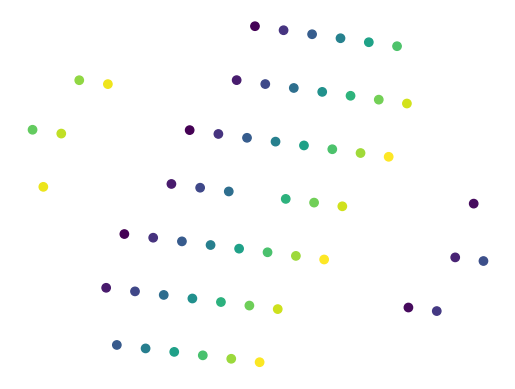

In [94]:
def calculate_projection(points, T_extrinsics, K_intrinsic, radius=1e-3, tolerance=1e-6):
    points_selected = points[np.linalg.norm(points, axis=1) < radius + tolerance]
    projected_x, projected_y, depth = project_points(points_selected, K_intrinsic, T_extrinsics)
    # cut using radius of edwald sphere
    idx = np.where(np.logical_and(depth < radius + tolerance, depth > radius - tolerance))[0]
    return projected_x[idx], projected_y[idx], depth[idx]

azimuth = np.pi/4 + 0.7
elevation = np.pi/6 + 1.4
camera_roll = 0.0
T_extrinsics = extrinsics_from_angles(azimuth, elevation, camera_roll, wavelength)
projected_x, projected_y, depth = calculate_projection(reflections, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

plt.scatter(projected_x, projected_y, c=depth, cmap='viridis')
plt.axis('off')

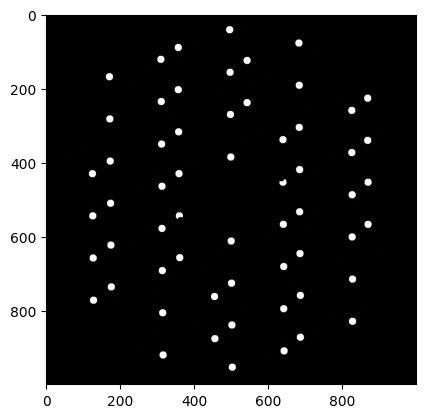

In [320]:
roll = 0.0
azimuth = np.pi/4 + 0.4
elevation = np.pi/6 + 1.4

T_extrinsics = extrinsics_from_angles(azimuth, elevation, camera_roll, wavelength)
projeted_x, projeted_y, depth = calculate_projection(reflections, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)
canvas_1 = draw_canvas(projeted_x, projeted_y, depth, canvas_size)[0]

roll_delta = 0.1
azimuth_delta = 0.1
elevation_delta = 0.1
T_extrinsics = extrinsics_from_angles(azimuth + azimuth_delta, elevation + elevation_delta, camera_roll + roll_delta, wavelength)
projeted_x, projeted_y, depth = calculate_projection(reflections, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)
canvas_2 = draw_canvas(projeted_x, projeted_y, depth, canvas_size)[0]

diff_img = canvas_1 - canvas_2
plt.imshow(diff_img, cmap='gray')

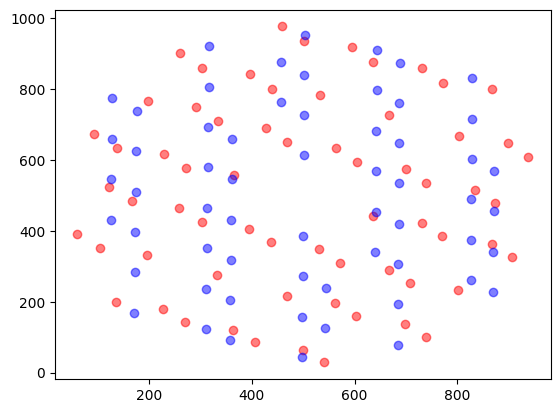

In [267]:
T_extrinsics = extrinsics_from_angles(azimuth, elevation, roll, wavelength)
projection_a = calculate_projection(reflections, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)
plt.scatter(projection_a[0], projection_a[1], color="red", alpha=0.5)


azimuth_delta = 0.1
elevation_delta = 0.1
roll_delta = 0.1
T_extrinsics = extrinsics_from_angles(azimuth + azimuth_delta, elevation + elevation_delta, roll + roll_delta, wavelength)
projection_b = calculate_projection(reflections, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)
plt.scatter(projection_b[0], projection_b[1], color="blue", alpha=0.5)


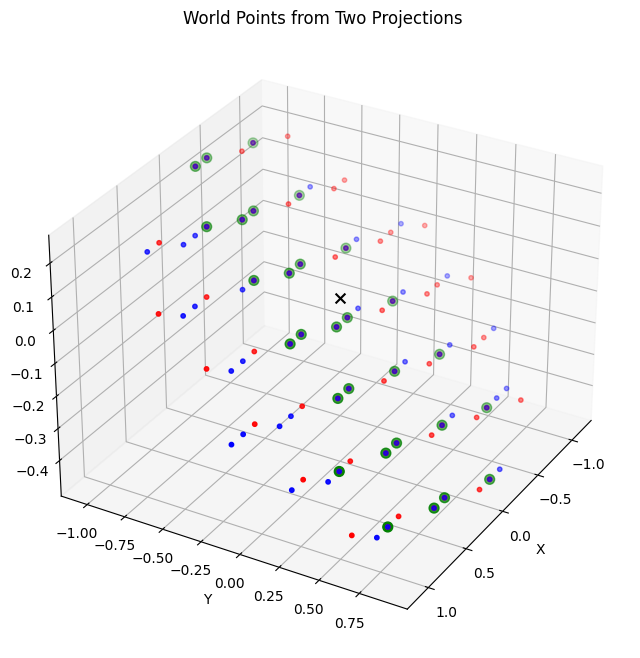

In [316]:
extrinsics_a = extrinsics_from_angles(azimuth, elevation, roll, wavelength)
projection_a = calculate_projection(reflections, np.linalg.inv(extrinsics_a), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

azimuth_delta = 0.1
elevation_delta = 0.0
roll_delta = 0.0
extrinsics_b = extrinsics_from_angles(azimuth + azimuth_delta, elevation + elevation_delta, roll + roll_delta, wavelength)
projection_b = calculate_projection(reflections, np.linalg.inv(extrinsics_b), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

projection_x_a, projection_y_a, depth_a = projection_a
projection_x_b, projection_y_b, depth_b = projection_b

world_pts_a = project_to_world(projection_x_a, projection_y_a, depth_a, K_intrinsic, np.linalg.inv(extrinsics_a))
world_pts_b = project_to_world(projection_x_b, projection_y_b, depth_b, K_intrinsic, np.linalg.inv(extrinsics_b))

intersections = []
for i in range(len(world_pts_a)):
    for j in range(len(world_pts_b)):
        if np.linalg.norm(world_pts_a[i] - world_pts_b[j]) < 1e-3:
            intersections.append((world_pts_a[i], world_pts_b[j]))

ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(world_pts_a[:, 0], world_pts_a[:, 1], world_pts_a[:, 2], color='red', label='World Points A', s=10)
ax.scatter(world_pts_b[:, 0], world_pts_b[:, 1], world_pts_b[:, 2], color='blue', label='World Points B', s=10)
ax.scatter([p[0][0] for p in intersections], [p[0][1] for p in intersections], [p[0][2] for p in intersections], color='green', label='Intersections', s=50, marker='o')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('World Points from Two Projections')
ax.view_init(elev=30, azim=30)
ax.scatter(0,0,0, color='black', label='Origin', s=50, marker='x')

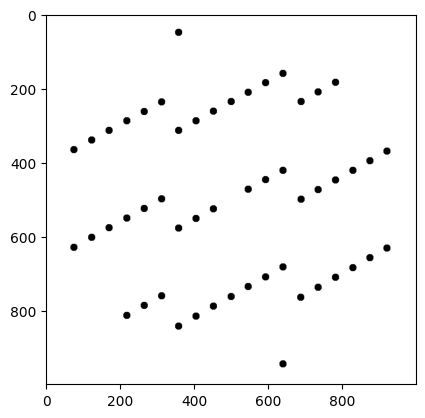

In [345]:
roll = 0.0
azimuth = 0
elevation = 0.0

T_extrinsics = extrinsics_from_angles(azimuth, elevation, camera_roll, wavelength)
projeted_x, projeted_y, depth = calculate_projection(reflections, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)
canvas = draw_canvas(projeted_x, projeted_y, depth, canvas_size)[0]

plt.imshow(canvas, cmap='gray')

Text(0.5, 1.0, 'Angular Intensity Profile')

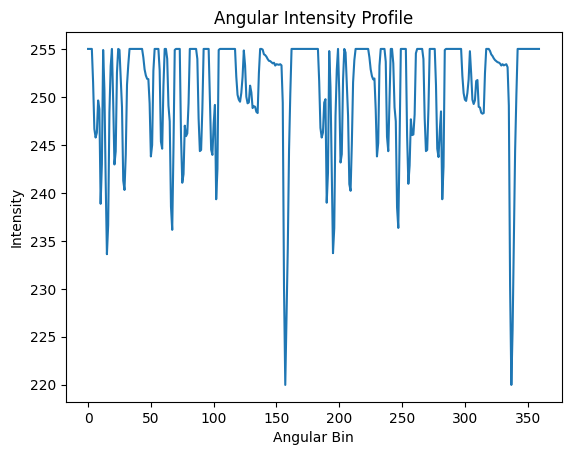

In [342]:
import numpy as np


def calculate_angular_intensity(
    canvas,
    center=None,
    num_angular_bins=6,
    reduction=np.sum,
):
    """
    Reduce image values in angular bins around a center.

    Parameters
    ----------
    canvas : np.ndarray
        2D image.

    center : tuple[float, float] | None
        Center as (x, y). Defaults to image center.

    num_angular_bins : int
        Number of equal angular sectors.

    reduction : callable
        Reduction function, e.g. np.sum, np.mean, np.max.

    Returns
    -------
    result : np.ndarray
        Reduced value for each angular sector.
        Sector 0 starts at angle 0 (positive x-axis).
    """

    H, W = canvas.shape

    if center is None:
        cx = (W - 1) / 2
        cy = (H - 1) / 2
    else:
        cx, cy = center

    # Pixel coordinates
    y, x = np.indices((H, W))

    # Angle of every pixel relative to center
    angles = np.arctan2(y - cy, x - cx)

    # Convert from [-pi, pi] to [0, 2*pi)
    angles = np.mod(angles, 2 * np.pi)

    # Assign every pixel to an angular bin
    bin_indices = (
        angles / (2 * np.pi) * num_angular_bins
    ).astype(int)

    # Reduce values in each angular bin
    result = np.empty(num_angular_bins, dtype=float)

    for i in range(num_angular_bins):
        values = canvas[bin_indices == i]

        if values.size:
            result[i] = reduction(values)
        else:
            result[i] = 0

    return result

angular_intensity = calculate_angular_intensity(canvas, center=None, num_angular_bins=360, reduction=np.mean)
plt.plot(angular_intensity)
plt.xlabel('Angular Bin')
plt.ylabel('Intensity')
plt.title('Angular Intensity Profile')

[141.  85.  83.  87.  87.  86.  88.  87.  90.  87.  90.  91.  93.  80.
 101.  95.  92.  93.  99.  99.  96.  99. 102. 104. 101. 105. 112. 109.
 111. 115. 121. 108. 127. 126. 129. 126. 136. 137. 141. 145. 148. 157.
 155. 163. 123. 221. 163. 155. 157. 148. 145. 141. 137. 136. 126. 129.
 126. 127. 108. 121. 115. 111. 109. 112. 105. 101. 104. 102.  99.  96.
  99.  99.  93.  92.  95. 101.  80.  93.  91.  90.  87.  90.  87.  88.
  86.  87.  87.  83.  85.  42. 140.  85.  83.  87.  87.  86.  88.  87.
  90.  87.  90.  91.  93.  80. 101.  95.  92.  93.  99.  99.  96.  99.
 102. 104. 101. 105. 112. 109. 111. 115. 121. 108. 127. 126. 129. 126.
 136. 137. 141. 145. 148. 157. 155. 163. 123. 224. 166. 158. 161. 151.
 148. 143. 140. 139. 128. 132. 129. 129. 110. 124. 117. 113. 112. 114.
 107. 103. 106. 104. 101.  98. 101. 101.  95.  94.  97. 103.  81.  95.
  93.  92.  89.  91.  89.  90.  88.  89.  88.  85.  87.  43. 142.  87.
  85.  88.  89.  88.  90.  89.  91.  89.  92.  93.  95.  81. 103.  97.
  94. 

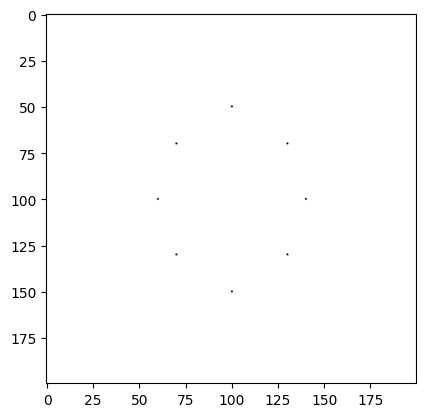

In [351]:

H, W = 200, 200
canvas = np.ones((H, W))

center = (100, 100)

# Put some dots at different angles
dots = [
    (140, 100),  # 0°
    (130, 130),  # ~45°
    (100, 150),  # 90°
    (70, 130),   # ~135°
    (60, 100),   # 180°
    (70, 70),    # ~225°
    (100, 50),   # 270°
    (130, 70),   # ~315°
]

# Give each dot a different intensity
for i, (x, y) in enumerate(dots):
    canvas[y, x] = 0


# ------------------------------------------------------------
# Calculate angular intensity
# ------------------------------------------------------------

result = calculate_angular_intensity(
    canvas,
    center=center,
    num_angular_bins=360,
    reduction=np.sum,
)

print(result)

plt.imshow(canvas, cmap='gray')

Text(0.5, 1.0, 'Angular Intensity Profile')

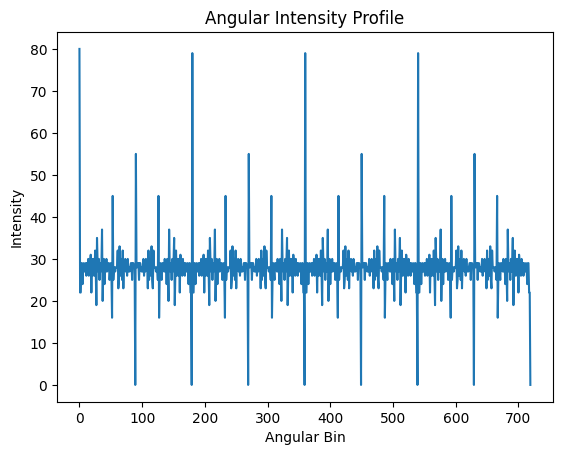

In [363]:
import numpy as np
import matplotlib.pyplot as plt


def calculate_angular_intensity(
    canvas,
    center=None,
    max_radius=None,
    num_angular_bins=6,
    reduction=np.sum,
):
    H, W = canvas.shape

    if center is None:
        cx = (W - 1) / 2
        cy = (H - 1) / 2
    else:
        cx, cy = center

    y, x = np.indices((H, W))

    # Distance and angle relative to center
    dx = x - cx
    dy = y - cy

    radius = np.sqrt(dx**2 + dy**2)
    angles = np.mod(np.arctan2(dy, dx), 2 * np.pi)

    # Restrict to circular region
    if max_radius is None:
        max_radius = radius.max()

    mask = radius <= max_radius

    # Angular bin for each pixel
    bin_indices = (
        angles / (2 * np.pi) * num_angular_bins
    ).astype(int)

    # Reduce values in each angular sector
    result = np.zeros(num_angular_bins)

    for i in range(num_angular_bins):
        values = canvas[
            mask & (bin_indices == i)
        ]

        if values.size:
            result[i] = reduction(values)

    return result


H, W = 200, 200
canvas = np.ones((H, W))

center = (100, 100)

# Put some dots at different angles
dots = [
    (140, 100),  # 0°
    (130, 130),  # ~45°
    (100, 150),  # 90°
    (70, 130),   # ~135°
    (60, 100),   # 180°
    (70, 70),    # ~225°
    (100, 50),   # 270°
    (130, 70),   # ~315°
]

# Give each dot a different intensity
for i, (x, y) in enumerate(dots):
    canvas[y, x] = 0


# ------------------------------------------------------------
# Calculate angular intensity
# ------------------------------------------------------------

result = calculate_angular_intensity(
    canvas,
    center=center,
    num_angular_bins=720,
    reduction=np.sum,
    max_radius=80
)

# plt.imshow(canvas, cmap='gray')
plt.plot(result)
plt.xlabel('Angular Bin')
plt.ylabel('Intensity')
plt.title('Angular Intensity Profile')

Text(0.5, 1.0, 'Angular Intensity Profile')

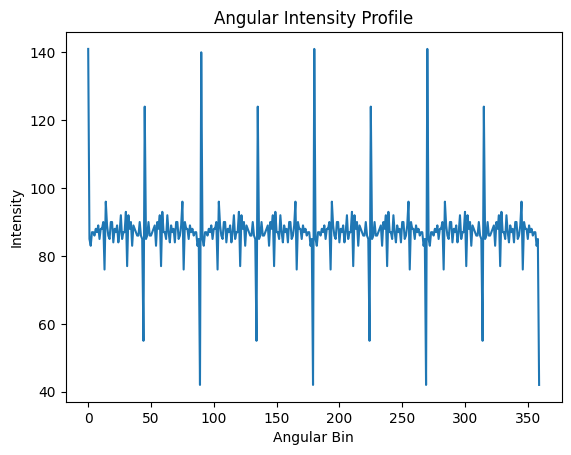

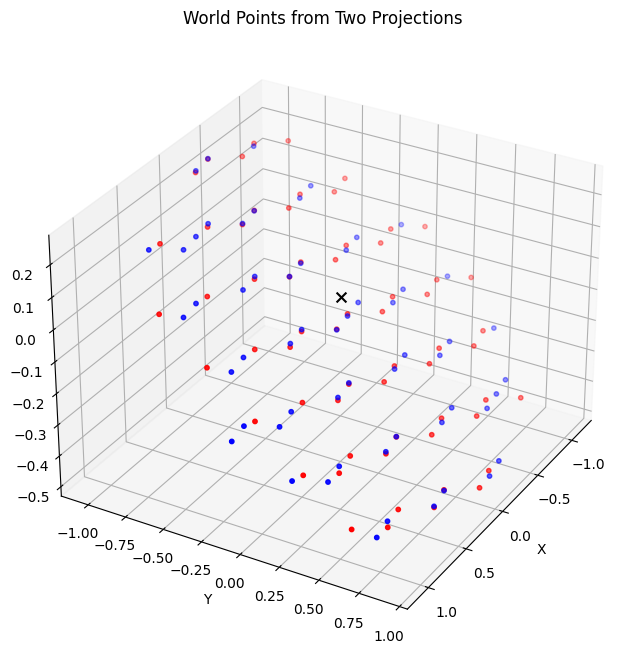

In [302]:
extrinsics_a = extrinsics_from_angles(azimuth, elevation, roll, wavelength)
projection_a = calculate_projection(reflections, np.linalg.inv(extrinsics_a), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

azimuth_delta = 0.1
elevation_delta = 0.0
roll_delta = 0.0
extrinsics_b = extrinsics_from_angles(azimuth + azimuth_delta, elevation + elevation_delta, roll + roll_delta, wavelength)
projection_b = calculate_projection(reflections, np.linalg.inv(extrinsics_b), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

projection_x_a, projection_y_a, _ = projection_a
projection_x_b, projection_y_b, _ = projection_b

depth_a = np.ones_like(projection_x_a) * 1 / wavelength * 0.1
depth_b = np.ones_like(projection_x_b) * 1 / wavelength * 0.1

world_pts_a = project_to_world(projection_x_a, projection_y_a, depth_a, K_intrinsic, np.linalg.inv(extrinsics_a))
world_pts_b = project_to_world(projection_x_b, projection_y_b, depth_b, K_intrinsic, np.linalg.inv(extrinsics_b))

ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(world_pts_a[:, 0], world_pts_a[:, 1], world_pts_a[:, 2], color='red', label='World Points A', s=10)
ax.scatter(world_pts_b[:, 0], world_pts_b[:, 1], world_pts_b[:, 2], color='blue', label='World Points B', s=10)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('World Points from Two Projections')
ax.view_init(elev=30, azim=30)
ax.scatter(0,0,0, color='black', label='Origin', s=50, marker='x')

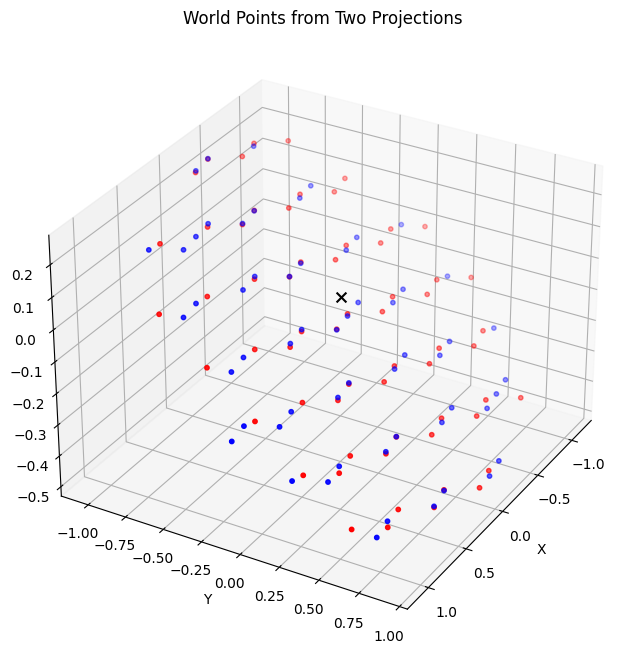

In [306]:
world_pts_a = project_to_world(projection_x_a, projection_y_a, depth_a, K_intrinsic, np.linalg.inv(extrinsics_a))
world_pts_b = project_to_world(projection_x_b, projection_y_b, depth_b, K_intrinsic, np.linalg.inv(extrinsics_b))

ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(world_pts_a[:, 0], world_pts_a[:, 1], world_pts_a[:, 2], color='red', label='World Points A', s=10)
ax.scatter(world_pts_b[:, 0], world_pts_b[:, 1], world_pts_b[:, 2], color='blue', label='World Points B', s=10)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('World Points from Two Projections')
ax.view_init(elev=30, azim=30)
ax.scatter(0,0,0, color='black', label='Origin', s=50, marker='x')

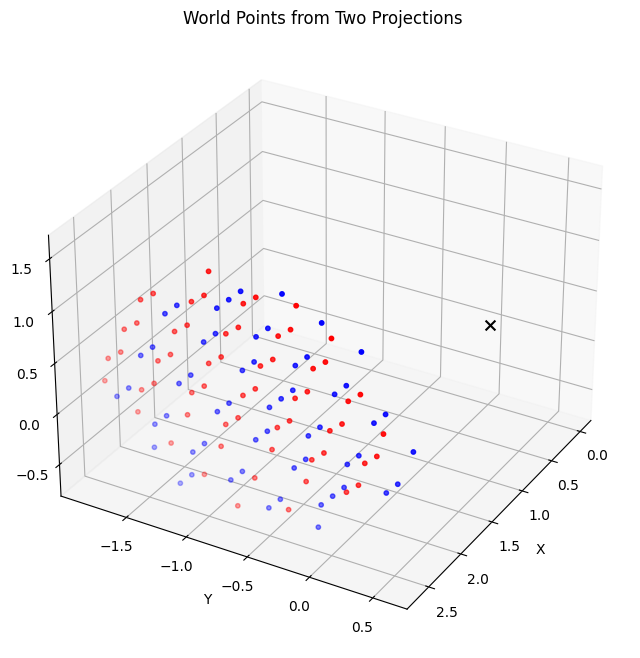

In [ ]:
world_pts_a = project_to_world(projection_x_a, projection_y_a, depth_a, K_intrinsic, np.linalg.inv(extrinsics_from_angles(0, 0, 0, wavelength)))
world_pts_b = project_to_world(projection_x_b, projection_y_b, depth_b, K_intrinsic, np.linalg.inv(extrinsics_from_angles(azimuth_delta, elevation_delta, roll_delta, wavelength)))

ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(world_pts_a[:, 0], world_pts_a[:, 1], world_pts_a[:, 2], color='red', label='World Points A', s=10)
ax.scatter(world_pts_b[:, 0], world_pts_b[:, 1], world_pts_b[:, 2], color='blue', label='World Points B', s=10)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('World Points from Two Projections')
ax.view_init(elev=30, azim=30)
ax.scatter(0,0,0, color='black', label='Origin', s=50, marker='x')

In [300]:
def calculate_matches(extrinsics_a, projection_a, extrinsics_b, projection_b, tolerance=1e-3):
    projection_x_a, projection_y_a, depth_a = projection_a
    projection_x_b, projection_y_b, depth_b = projection_b

    world_pts_a = project_to_world(projection_x_a, projection_y_a, depth_a, K_intrinsic, np.linalg.inv(extrinsics_a))
    world_pts_b = project_to_world(projection_x_b, projection_y_b, depth_b, K_intrinsic, np.linalg.inv(extrinsics_b))

    matches = []
    for i, point_a in enumerate(world_pts_a):
        for j, point_b in enumerate(world_pts_b):
            if np.linalg.norm(point_a - point_b) < tolerance:
                matches.append((i, j))
                break

    return matches

extrinsics_a = extrinsics_from_angles(azimuth, elevation, camera_roll, wavelength)
projection_a = calculate_projection(reflections, np.linalg.inv(extrinsics_a), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

roll_delta = 0.1
azimuth_delta = 0.0
elevation_delta = 0.0
extrinsics_b = extrinsics_from_angles(azimuth + azimuth_delta, elevation + elevation_delta, camera_roll + roll_delta, wavelength)
projection_b = calculate_projection(reflections, np.linalg.inv(extrinsics_b), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

calculated_matches = calculate_matches(extrinsics_a, projection_a, extrinsics_b, projection_b, tolerance=1e-1)
len(calculated_matches)

28

In [291]:
def estimate_matches(projection_x_a, projection_y_a, extrinsics_a, projection_x_b, projection_y_b, extrinsics_b, tolerance=1e-3):
    depth_a = np.ones_like(projection_x_a) * 1 / wavelength * 0.1
    depth_b = np.ones_like(projection_x_b) * 1 / wavelength * 0.1

    world_pts_a = project_to_world(projection_x_a, projection_y_a, depth_a, K_intrinsic, np.linalg.inv(extrinsics_a))
    world_pts_b = project_to_world(projection_x_b, projection_y_b, depth_b, K_intrinsic, np.linalg.inv(extrinsics_b))

    matches = []
    for i, point_a in enumerate(world_pts_a):
        for j, point_b in enumerate(world_pts_b):
            if np.linalg.norm(point_a - point_b) < tolerance:
                matches.append((i, j))
                break

    return matches

extrinsics_a = extrinsics_from_angles(azimuth, elevation, roll, wavelength)
projection_a = calculate_projection(reflections, np.linalg.inv(extrinsics_a), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

roll_delta = 0.1
azimuth_delta = 0.0
elevation_delta = 0.0
extrinsics_b = extrinsics_from_angles(azimuth + azimuth_delta, elevation + elevation_delta, roll + roll_delta, wavelength)
projection_b = calculate_projection(reflections, np.linalg.inv(extrinsics_b), K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error)

estimated_matches = estimate_matches(projection_a[0], projection_a[1], extrinsics_a, projection_b[0], projection_b[1], extrinsics_b, tolerance=1e-1)
len(estimated_matches)

28

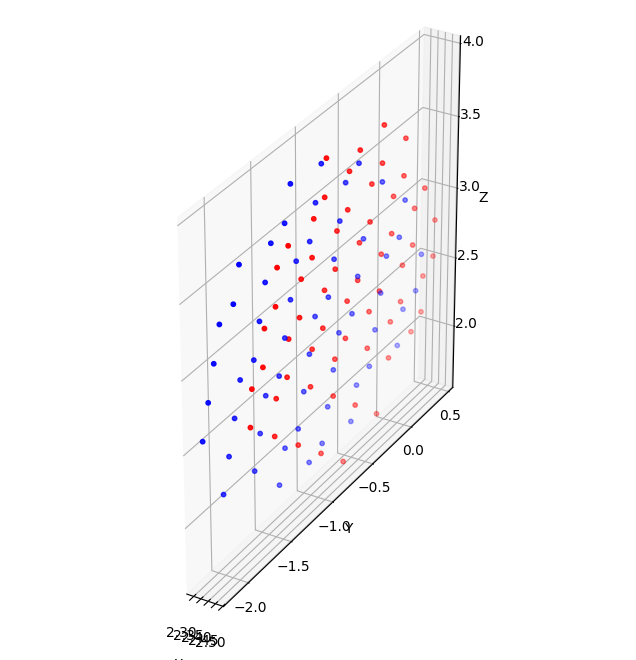

In [301]:
extrinsics_a = extrinsics_from_angles(0.0, 0.0, 0.0, wavelength)  # Assuming projection_a is fixed and corresponds to the original extrinsics
extrinsics_b = extrinsics_from_angles(azimuth_delta, elevation_delta, roll_delta, wavelength)

world_pts_a = project_to_world(projection_a[0], projection_a[1], projection_a[2], K_intrinsic, np.linalg.inv(extrinsics_a))
world_pts_b = project_to_world(projection_b[0], projection_b[1], projection_b[2], K_intrinsic, np.linalg.inv(extrinsics_b))

ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(world_pts_a[:, 0], world_pts_a[:, 1], world_pts_a[:, 2], color='red', label='World Points A', s=10)
ax.scatter(world_pts_b[:, 0], world_pts_b[:, 1], world_pts_b[:, 2], color='blue', label='World Points B', s=10)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_aspect('equal')

In [264]:
from scipy.optimize import minimize

def objective_function(params, projection_a, projection_b):
    azimuth, elevation, roll = params
    extrinsics_a = extrinsics_from_angles(0.0, 0.0, 0.0, wavelength)  # Assuming projection_a is fixed and corresponds to the original extrinsics
    extrinsics_b = extrinsics_from_angles(azimuth, elevation, roll, wavelength)
    matches = estimate_matches(projection_a[0], projection_a[1], extrinsics_a, projection_b[0], projection_b[1], extrinsics_b, tolerance=1e-3)
    return -len(matches)  # We want to maximize the number of matches

objective_function([0, 0, 0.1], projection_a, projection_b)

0

In [263]:
x0 = [0,0,0] # Initial guess for azimuth, elevation, roll

result = minimize(objective_function, x0, args=(projection_a, projection_b), method='Nelder-Mead', options={'maxiter': 100, 'disp': True})

print("Optimization result:", result)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 3
         Function evaluations: 14
Optimization result:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.0
             x: [ 0.000e+00  0.000e+00  0.000e+00]
           nit: 3
          nfev: 14
 final_simplex: (array([[ 0.000e+00,  0.000e+00,  0.000e+00],
                       [ 6.250e-05,  0.000e+00,  0.000e+00],
                       [ 0.000e+00,  6.250e-05,  0.000e+00],
                       [ 0.000e+00,  0.000e+00,  6.250e-05]]), array([ 0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00]))


In [73]:
from scipy.optimize import minimize

def fun(params):
    azimuth, elevation = params
    T_extrinsics = extrinsics_from_angles(azimuth, elevation, wavelength)
    constant_depth = np.ones_like(projected_x) * 1 / wavelength * 0.1
    world_pts_homogeneous = project_to_world(projected_x, projected_y, constant_depth, K_intrinsic, T_extrinsics)
    return (world_pts_homogeneous - diffraction_spots).ravel()

minimize(fun, x0=[azimuth, elevation], method='Nelder-Mead', options={'maxiter': 1000, 'disp': True})

ValueError: operands could not be broadcast together with shapes (34,3) (49,3) 